# DOE-004
## 単純ロスカット調査 - 基礎調査
- 対象銘柄: 9984
- PPF (Pure Pursuit Folloewer) vs SMA vs EMA
- トレーリング・ストップ利確
    - THRESHOLD_TRAILING: トレーリング・ストップするしきい値
- ロスカット
    - LOSSCUT_VWAP: VWAP 基準でロスカット
- クロス・シグナルのエントリ・エグジット
- 評価指標
    - 収益と約定回数

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
name_doe = "doe-004"
date_trade = "20260911"
name_code = "9984"
csvfile = f"../doe/{name_doe}/{date_trade}_{name_code}.csv"
df = pd.read_csv(csvfile)
df

,TYPE_MA_1,THRESHOLD_TRAILING,LOSSCUT_VWAP,Profit,Transactions
0,PPF,0.4,2,-79.0,40.0
1,PPF,0.5,2,-69.0,40.0
2,PPF,0.6,2,-40.0,40.0
3,PPF,0.7,2,-34.0,40.0
4,PPF,0.8,2,-40.0,40.0
...,...,...,...,...,...
160,EMA,0.4,-18,-104.0,56.0
161,EMA,0.5,-18,-64.0,56.0
162,EMA,0.6,-18,-47.0,56.0
163,EMA,0.7,-18,-42.0,56.0


In [3]:
profit_max = df["Profit"].max()
df[df["Profit"] == profit_max]

,TYPE_MA_1,THRESHOLD_TRAILING,LOSSCUT_VWAP,Profit,Transactions
44,PPF,0.8,-14,65.0,26.0


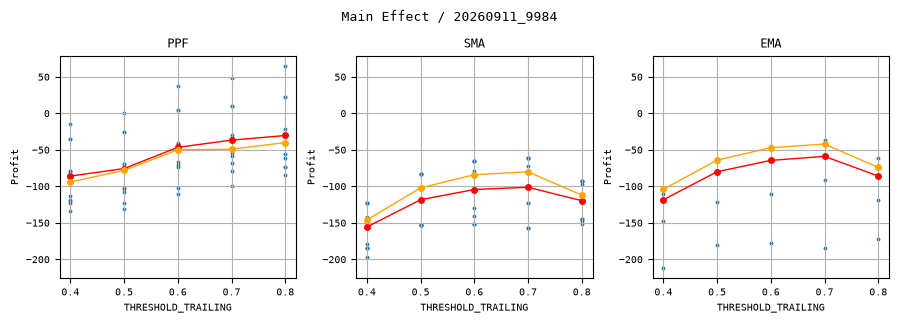

In [4]:
plt.rcParams["font.family"] = "monospace"
plt.rcParams["font.size"] = 7

fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))

name_x = "THRESHOLD_TRAILING"
name_y = "Profit"
y_min0 = df[name_y].min()
y_max0 = df[name_y].max()
pad = (y_max0 - y_min0) * 0.05
y_min = y_min0 - pad
y_max = y_max0 + pad
list_type = ["PPF", "SMA", "EMA"]
for ax, name_type in zip(axes, list_type):
    df1 = df[df["TYPE_MA_1"] == name_type]
    ax.scatter(df1[name_x], df1[name_y], s=3)

    # x の各水準ごとの平均値
    mean = df1.groupby(name_x)[name_y].mean()
    # 平均値を線で結ぶ
    ax.plot(
        mean.index,
        mean.values,
        "o-",
        color="red",
        markersize=4,
        linewidth=1,
    )
    # x の各水準ごとのメジアン
    median = df1.groupby(name_x)[name_y].median()
    # 平均値を線で結ぶ
    ax.plot(
        median.index,
        median.values,
        "o-",
        color="orange",
        markersize=4,
        linewidth=1,
    )
    
    ax.set_title(name_type)
    ax.set(xlabel=name_x, ylabel=name_y)
    ax.set_ylim(y_min, y_max)
    ax.grid(True)

fig.suptitle(f"Main Effect / {date_trade}_{name_code}", fontsize=9)

plt.tight_layout()
pngfile = f"../doe/{name_doe}/{date_trade}_{name_code}_main_effect_{name_x}_{name_y}.png"
plt.savefig(pngfile)
plt.show()

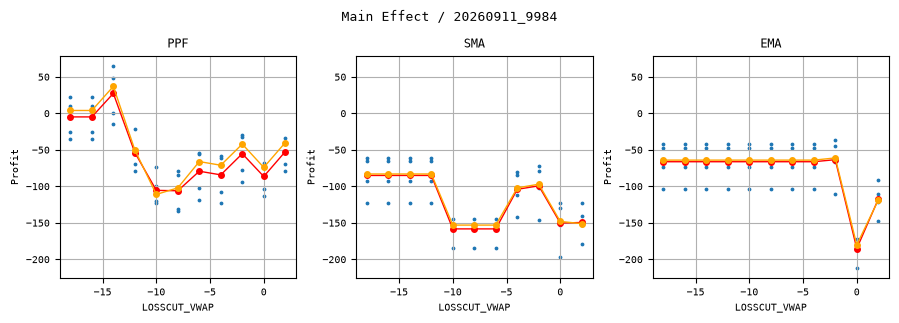

In [5]:
plt.rcParams["font.family"] = "monospace"
plt.rcParams["font.size"] = 7

fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))

name_x = "LOSSCUT_VWAP"
name_y = "Profit"
y_min0 = df[name_y].min()
y_max0 = df[name_y].max()
pad = (y_max0 - y_min0) * 0.05
y_min = y_min0 - pad
y_max = y_max0 + pad
list_type = ["PPF", "SMA", "EMA"]
for ax, name_type in zip(axes, list_type):
    df1 = df[df["TYPE_MA_1"] == name_type]
    ax.scatter(df1[name_x], df1[name_y], s=3)

    # x の各水準ごとの平均値
    mean = df1.groupby(name_x)[name_y].mean()
    # 平均値を線で結ぶ
    ax.plot(
        mean.index,
        mean.values,
        "o-",
        color="red",
        markersize=4,
        linewidth=1,
    )
    # x の各水準ごとのメジアン
    median = df1.groupby(name_x)[name_y].median()
    # 平均値を線で結ぶ
    ax.plot(
        median.index,
        median.values,
        "o-",
        color="orange",
        markersize=4,
        linewidth=1,
    )
    
    ax.set_title(name_type)
    ax.set(xlabel=name_x, ylabel=name_y)
    ax.set_ylim(y_min, y_max)
    ax.grid(True)

fig.suptitle(f"Main Effect / {date_trade}_{name_code}", fontsize=9)

plt.tight_layout()
pngfile = f"../doe/{name_doe}/{date_trade}_{name_code}_main_effect_{name_x}_{name_y}.png"
plt.savefig(pngfile)
plt.show()

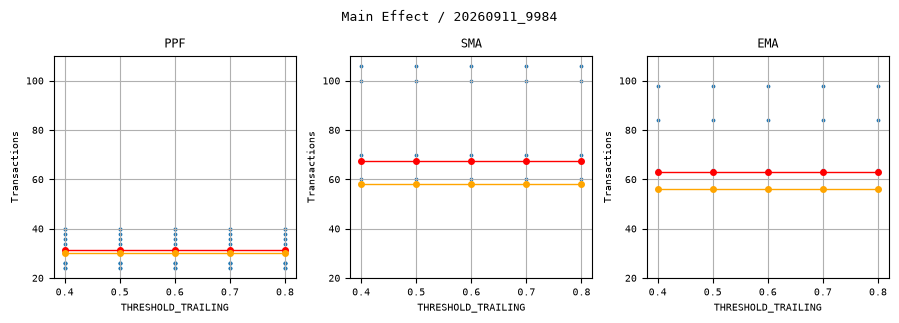

In [6]:
plt.rcParams["font.family"] = "monospace"
plt.rcParams["font.size"] = 7

fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))

name_x = "THRESHOLD_TRAILING"
name_y = "Transactions"
y_min0 = df[name_y].min()
y_max0 = df[name_y].max()
pad = (y_max0 - y_min0) * 0.05
y_min = y_min0 - pad
y_max = y_max0 + pad
list_type = ["PPF", "SMA", "EMA"]
for ax, name_type in zip(axes, list_type):
    df1 = df[df["TYPE_MA_1"] == name_type]
    ax.scatter(df1[name_x], df1[name_y], s=3)

    # x の各水準ごとの平均値
    mean = df1.groupby(name_x)[name_y].mean()
    # 平均値を線で結ぶ
    ax.plot(
        mean.index,
        mean.values,
        "o-",
        color="red",
        markersize=4,
        linewidth=1,
    )
    # x の各水準ごとのメジアン
    median = df1.groupby(name_x)[name_y].median()
    # 平均値を線で結ぶ
    ax.plot(
        median.index,
        median.values,
        "o-",
        color="orange",
        markersize=4,
        linewidth=1,
    )
    
    ax.set_title(name_type)
    ax.set(xlabel=name_x, ylabel=name_y)
    ax.set_ylim(y_min, y_max)
    ax.grid(True)

fig.suptitle(f"Main Effect / {date_trade}_{name_code}", fontsize=9)

plt.tight_layout()
pngfile = f"../doe/{name_doe}/{date_trade}_{name_code}_main_effect_{name_x}_{name_y}.png"
plt.savefig(pngfile)
plt.show()

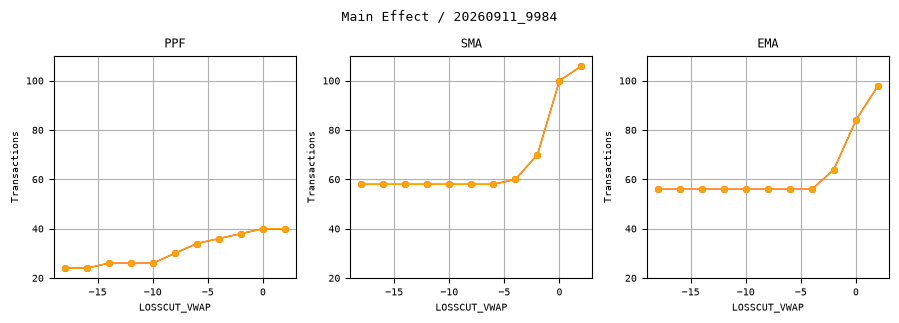

In [7]:
plt.rcParams["font.family"] = "monospace"
plt.rcParams["font.size"] = 7

fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))

name_x = "LOSSCUT_VWAP"
name_y = "Transactions"
y_min0 = df[name_y].min()
y_max0 = df[name_y].max()
pad = (y_max0 - y_min0) * 0.05
y_min = y_min0 - pad
y_max = y_max0 + pad
list_type = ["PPF", "SMA", "EMA"]
for ax, name_type in zip(axes, list_type):
    df1 = df[df["TYPE_MA_1"] == name_type]
    ax.scatter(df1[name_x], df1[name_y], s=3)

    # x の各水準ごとの平均値
    mean = df1.groupby(name_x)[name_y].mean()
    # 平均値を線で結ぶ
    ax.plot(
        mean.index,
        mean.values,
        "o-",
        color="red",
        markersize=4,
        linewidth=1,
    )
    # x の各水準ごとのメジアン
    median = df1.groupby(name_x)[name_y].median()
    # 平均値を線で結ぶ
    ax.plot(
        median.index,
        median.values,
        "o-",
        color="orange",
        markersize=4,
        linewidth=1,
    )
    
    ax.set_title(name_type)
    ax.set(xlabel=name_x, ylabel=name_y)
    ax.set_ylim(y_min, y_max)
    ax.grid(True)

fig.suptitle(f"Main Effect / {date_trade}_{name_code}", fontsize=9)

plt.tight_layout()
pngfile = f"../doe/{name_doe}/{date_trade}_{name_code}_main_effect_{name_x}_{name_y}.png"
plt.savefig(pngfile)
plt.show()